<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/01_veri_inceleme_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!ls /content/drive/MyDrive/Colab\ Notebooks/

ls: cannot access '/content/drive/MyDrive/Colab Notebooks/': No such file or directory


In [6]:
ANA = '/content/drive/MyDrive/436543_Enes_Kok/cepte-veterinerlik'
RAW = ANA + '/raw'

!ls -lh "{RAW}"

ls: cannot access '/content/drive/MyDrive/436543_Enes_Kok/cepte-veterinerlik/raw': No such file or directory


In [7]:
!ls /content/drive
!echo "-----"
!ls /content/drive/MyDrive


MyDrive
-----
 436543_Enes_kok  'çalışmalarım '   Classroom   creatiny   ETT	'yapay zeka'


In [8]:
ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'
RAW = ANA + '/raw'

!ls -lh "{RAW}"

total 155M
-rw------- 1 root root 155M Oct 13 06:42 'Lumpy Skin Images Dataset.zip'


In [9]:
!mkdir -p /content/data/mendeley
!unzip -q "{RAW}"/*.zip -d /content/data/mendeley
!ls /content/data/mendeley


'Lumpy Skin Images Dataset'


In [10]:
import os

VERI = '/content/data/mendeley'

for klasor, alt_klasorler, dosyalar in os.walk(VERI):
    resimler = [d for d in dosyalar if d.lower().endswith(('.png', '.jpg', '.jpeg'))]
    digerleri = [d for d in dosyalar if d not in resimler]
    print(klasor.replace(VERI, ''), '->', len(resimler), 'görüntü', '| diğer dosyalar:', digerleri[:5])

 -> 0 görüntü | diğer dosyalar: []
/Lumpy Skin Images Dataset -> 0 görüntü | diğer dosyalar: ['Lumpy Skin Images Dataset.zip']


Bu kısım da da yanlış klasörü indirdiğimizi görüyoruz.Çünkü 0 görüntü çıktı.Mendeley data sitemizden yanlış klasörü indirdiğimizi görüyoruz.
Ya da içerisinde tekrar bi zip dosyası var şimdi onu bulmaya çalışacağız.


In [11]:
!find /content/data/mendeley -name "*.zip"

/content/data/mendeley/Lumpy Skin Images Dataset/Lumpy Skin Images Dataset.zip


In [12]:
import glob, zipfile

for zip_yolu in glob.glob('/content/data/mendeley/**/*.zip', recursive=True):
    print('Açılıyor:', zip_yolu)
    with zipfile.ZipFile(zip_yolu) as z:
        z.extractall('/content/data/mendeley')
    os.remove(zip_yolu)

print('Bitti')

Açılıyor: /content/data/mendeley/Lumpy Skin Images Dataset/Lumpy Skin Images Dataset.zip
Bitti


Evet aynen dediğimiz gibi zip içerisinde zip dosyamız çıktı.Yukarıdaki kod içerisinde ne kadar derinde olursa olsun ,zip ile biten tüm dosyaları bulmasını istedik ve gerçekten bu sefer buldu.
"**" çift yıldızın anlamı her alt klasör demektir.

In [13]:
import os

VERI = '/content/data/mendeley'

for klasor, alt_klasorler, dosyalar in os.walk(VERI):
    resimler = [d for d in dosyalar if d.lower().endswith(('.png', '.jpg', '.jpeg'))]
    digerleri = [d for d in dosyalar if d not in resimler]
    print(klasor.replace(VERI, ''), '->', len(resimler), 'görüntü', '| diğer dosyalar:', digerleri[:5])

 -> 0 görüntü | diğer dosyalar: []
/Lumpy Skin -> 324 görüntü | diğer dosyalar: []
/Normal Skin -> 700 görüntü | diğer dosyalar: []
/Lumpy Skin Images Dataset -> 0 görüntü | diğer dosyalar: []


Evet çıktımızdan da anlıyoruz ki 0 görüntü yazan kısım en üst klasörüm benim. Alt klasörlerimdeki değerler de bu verisetimin içeriğiyle aynı cıkmıs durumda.İşlem başarılı devam edelimm.

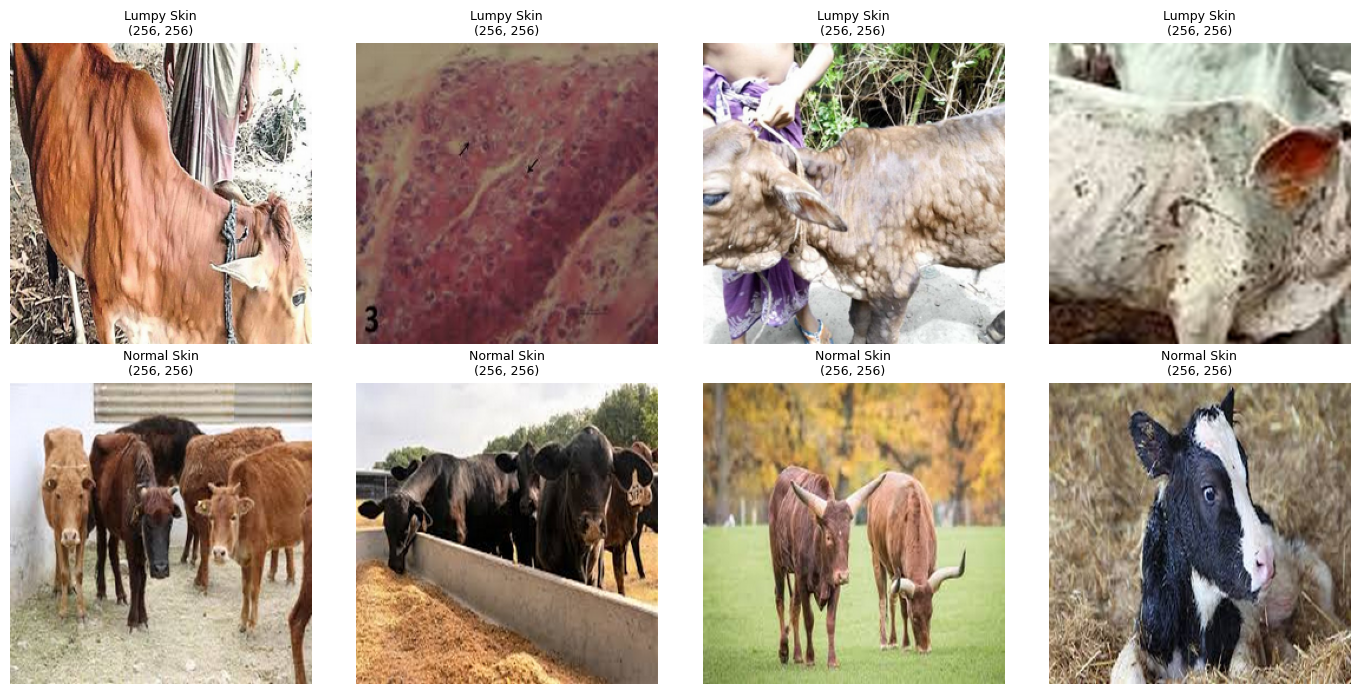

In [14]:
import glob, random
import matplotlib.pyplot as plt
from PIL import Image

siniflar = ['Lumpy Skin', 'Normal Skin']
fig, eksenler = plt.subplots(2, 4, figsize=(14, 7))

for satir, sinif in enumerate(siniflar):
    yollar = glob.glob(f'{VERI}/**/{sinif}/*.png', recursive=True)
    for sutun, yol in enumerate(random.sample(yollar, 4)):
        resim = Image.open(yol)
        eksenler[satir, sutun].imshow(resim)
        eksenler[satir, sutun].set_title(f'{sinif}\n{resim.size}', fontsize=9)
        eksenler[satir, sutun].axis('off')

plt.tight_layout()
plt.show()